In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/iris")

print("Path to dataset files:", path,"/Iris.csv")

Using Colab cache for faster access to the 'iris' dataset.
Path to dataset files: /kaggle/input/iris /Iris.csv


In [ ]:
df = pd.read_csv("/kaggle/input/iris/Iris.csv")
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [ ]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


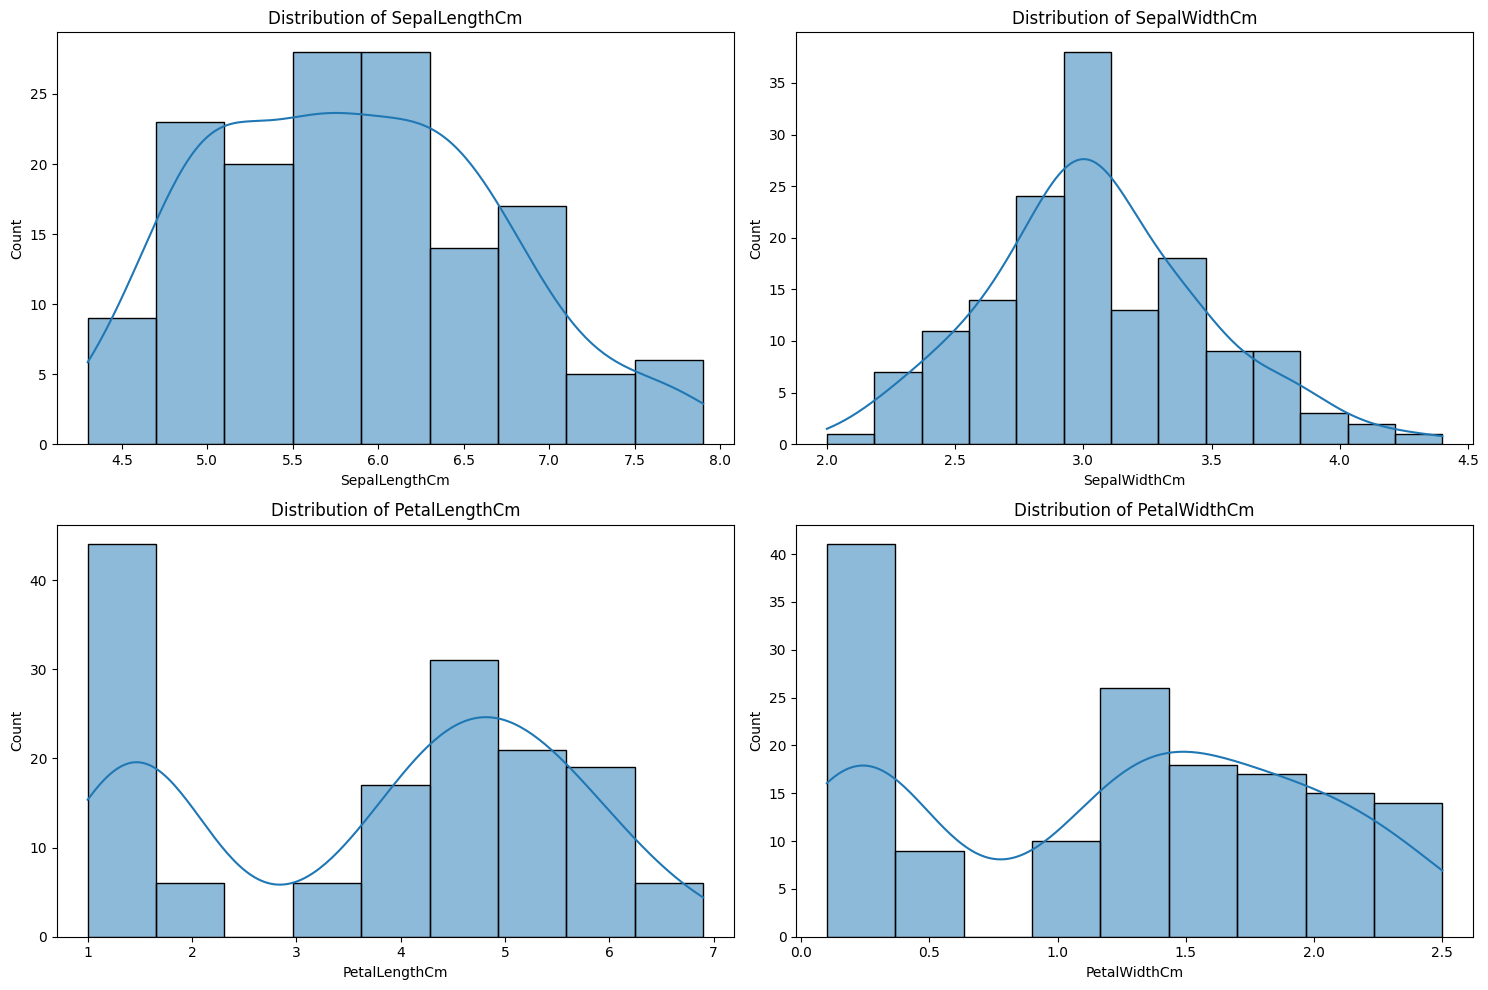

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(df.columns[1:-1]):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

In [ ]:
%pip install -q outlier-tool-shashikant

In [ ]:
from outlier_tool import Outliers
o = Outliers(df)

In [ ]:
o.find("iqr")

,column,method,lower,upper,outliers,percent
0,Id,iqr,-73.50,224.50,0,0.00
1,SepalLengthCm,iqr,3.15,8.35,0,0.00
2,SepalWidthCm,iqr,2.05,4.05,4,2.67
3,PetalLengthCm,iqr,-3.65,10.35,0,0.00
4,PetalWidthCm,iqr,-1.95,4.05,0,0.00


<Axes: ylabel='SepalWidthCm'>

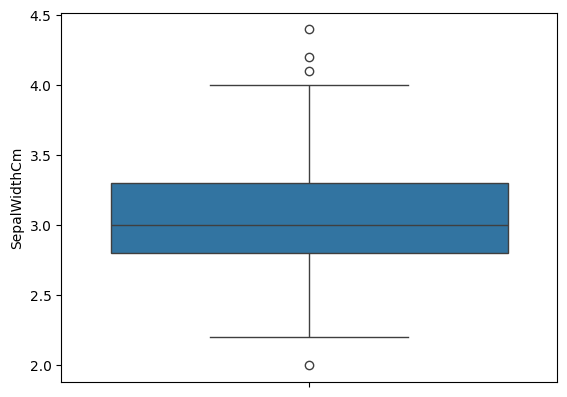

In [ ]:
sns.boxplot(df['SepalWidthCm'])

In [ ]:
X = df1.iloc[:, 1:-1]
y = df1.iloc[:, -1]

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=9)

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

GNB = GaussianNB()
GNB.fit(X_train, y_train)
yprid = GNB.predict(X_test)

accuracy = accuracy_score(y_test, yprid)
print("Accuracy:", accuracy)

cm = confusion_matrix(y_test, yprid)
print("Confusion Matrix:\n", cm)

cr = classification_report(y_test, yprid)
print("Classification Report:\n", cr)

train = GNB.score(X_train, y_train)
print("Training Score:", train)

test = GNB.score(X_test, y_test)
print("Testing Score:", test)

Accuracy: 1.0
Confusion Matrix:
 [[15  0  0]
 [ 0 13  0]
 [ 0  0 10]]
Classification Report:
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       1.00      1.00      1.00        13
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        38
      macro avg       1.00      1.00      1.00        38
   weighted avg       1.00      1.00      1.00        38

Training Score: 0.9553571428571429
Testing Score: 1.0


In [ ]:
new = {}
for col in X.columns:
  value = input(f"Enter {col}: ")
  # Convert inputs to float since all features in X are numeric measurements
  new[col] = [float(value)]

new_df = pd.DataFrame(new)

# Make prediction using the trained GaussianNB model (GNB)
predictions = GNB.predict(new_df)[0]
probability = GNB.predict_proba(new_df)[0]

print(f"\n\t Prediction: {predictions}")

# Print the probabilities for each class
print("\t Class Probabilities:")
for class_name, prob in zip(GNB.classes_, probability):
    print(f"\t - {class_name}: {round(prob * 100, 2)}%")

Enter SepalLengthCm: 2.0
Enter SepalWidthCm: 853.0
Enter PetalLengthCm: 14.
Enter PetalWidthCm: 1.0

	 Prediction: Iris-setosa
	 Class Probabilities:
	 - Iris-setosa: 100.0%
	 - Iris-versicolor: 0.0%
	 - Iris-virginica: 0.0%
